# Cobertura, vieses e silêncios

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/andrelfo85/Atividade_Goodreads/blob/master/unidade_02/02_cobertura_vieses_e_silencios.ipynb)

O Notebook 01 produziu critérios e um corpus. Agora a atenção se desloca
da clareza das regras para suas consequências: quem, o quê e quais
contextos permanecem visíveis depois da seleção.

## 1. Cobertura não é sinônimo de representatividade

**Cobertura** descreve quais períodos, lugares, instituições, tipos
documentais ou grupos aparecem na base. **Representatividade** é uma
afirmação mais forte: depende da população, do mecanismo de seleção e do
tipo de inferência pretendida. Um corpus pode ter boa cobertura temporal e
ainda excluir sistematicamente determinadas experiências.

Para interpretar uma cobertura incompleta, não basta contar lacunas. É
preciso localizar em que etapa cada ausência surgiu, pois ausências
históricas, ausências na base e valores vazios exigem respostas distintas.

In [1]:
# @title Preparação do ambiente — execute esta célula no Google Colab
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

URL_REPOSITORIO = 'https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais.git'
REPOSITORIO = Path(
    "/content/disciplina_computacao_aplicada_humanidades_digitais"
)
PASTA_UNIDADE = REPOSITORIO / 'unidade_02'

try:
    import google.colab  # type: ignore  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    if not (REPOSITORIO / ".git").exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "main",
                URL_REPOSITORIO,
                str(REPOSITORIO),
            ],
            check=True,
        )

    PACOTES_COLAB = []
    ausentes = [
        especificacao
        for modulo, especificacao in PACOTES_COLAB
        if importlib.util.find_spec(modulo) is None
    ]
    if ausentes:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *ausentes],
            check=True,
        )

    os.chdir(PASTA_UNIDADE)
    print("Ambiente preparado em:", Path.cwd())
else:
    print("Ambiente local: nenhuma clonagem necessária.")

Ambiente preparado em: /content/disciplina_computacao_aplicada_humanidades_digitais/unidade_02


## 2. Três ausências diferentes

| Situação | Exemplo | Consequência |
|---|---|---|
| ausência no registro histórico | uma experiência não foi documentada | não pode ser corrigida preenchendo uma célula |
| ausência na base | fonte existente não foi localizada ou selecionada | requer busca, novo acesso ou revisão do recorte |
| valor ausente | campo não preenchido em registro incluído | requer diagnóstico e regra de tratamento |

A cadeia abaixo localiza as ausências no processo que vai da experiência
vivida ao campo preenchido na base.

![Cadeia da experiência ao registro, à preservação, à base e ao campo preenchido; entre as etapas aparecem ausência no registro histórico, perda de preservação, ausência na base e valor ausente.](https://github.com/andrelfo85/Atividade_Goodreads/blob/master/unidade_02/imagens/02_cadeia_ausencias.svg?raw=1)

Silêncios documentais também são efeitos de poder: quem podia registrar,
preservar, classificar e autorizar acesso? Trouillot (1995) situa silêncios
em diferentes momentos da produção histórica; Schwartz e Cook (2002)
discutem arquivos, memória e poder.

Com essas distinções conceituais, podemos comparar empiricamente o universo
acessível e o corpus. A comparação não recupera o que nunca foi registrado,
mas mostra o que as decisões do projeto fizeram desaparecer ou diminuir.

## 3. Comparar universo acessível e corpus

Vamos reutilizar os critérios do notebook anterior e comparar distribuições.
Contagens pequenas não medem importância social; tornam perdas de cobertura
visíveis para revisão.

In [2]:
 import pandas as pd

catalogo = pd.read_csv("dados/catalogo_fontes.csv")
corpus = catalogo[
    catalogo["ano"].between(1890, 1900)
    & catalogo["localizado"].eq("sim")
    & catalogo["digitalizado"].eq("sim")
    & catalogo["condicao_acesso"].isin(
        ["público", "mediante autorização"]
    )
].copy()

cobertura = pd.concat(
    [
        catalogo["grupo_representado"].value_counts().rename("catálogo"),
        corpus["grupo_representado"].value_counts().rename("corpus"),
    ],
    axis=1,
).fillna(0).astype(int)
cobertura

,catálogo,corpus
grupo_representado,,
público leitor,5,4
elite administrativa,3,2
trabalhadores,2,1
associação comunitária,2,1
mulheres associadas,2,1
família proprietária,2,0


O cálculo fornece a comparação; a leitura a seguir delimita o que ela pode
e não pode sustentar como evidência.

### U02-A04 — Atividade guiada — leitura da comparação

A visualização retoma os valores calculados e permite perceber rapidamente
quais grupos diminuem ou desaparecem após a aplicação dos critérios.

![Barras comparam grupos no catálogo e no corpus: família proprietária cai de dois para zero, trabalhadores de dois para um e público leitor de cinco para quatro.](https://github.com/andrelfo85/Atividade_Goodreads/blob/master/unidade_02/imagens/02_cobertura_catalogo_corpus.svg?raw=1)

A tabela não revela diretamente a composição da população histórica. Ela
revela como decisões de localização, digitalização, acesso e período
alteram este catálogo fictício. Identifique grupos que desaparecem,
diminuem ou permanecem e associe cada mudança a uma etapa da seleção.

**Segue abaixo minha leitura:**

| Grupo | Catálogo → corpus | Situação | Etapa da seleção responsável |
|---|---|---|---|
| família proprietária | 2 → 0 | desaparece | D001: não localizado, sem digitalização e sem autorização; D002: fora do período (1903), sem digitalização e acesso restrito |
| trabalhadores | 2 → 1 | diminui pela metade | A003: sem digitalização e acesso restrito |
| associação comunitária | 2 → 1 | diminui pela metade | B003 (fotografia): sem digitalização |
| mulheres associadas | 2 → 1 | diminui pela metade | B004: fora do período (1902) |
| elite administrativa | 3 → 2 | diminui | A005: fora do período (1901) |
| público leitor | 5 → 4 | diminui | C005: fora do período (1904) e sem digitalização |

Faço três observações. Primeiro, a perda não é uniforme: grupos com poucos
registros perdem proporcionalmente mais (metade ou tudo), enquanto o público
leitor mantém 80%. Segundo, a digitalização é a regra que mais exclui e atinge
justamente fontes de instituições com menos recursos (ex: coleção particular e
museu comunitário). Terceiro, os diários do grupo 'família proprietária' desaparecem por uma combinação de localização, acesso e período; a ausência no corpus não significa que o grupo não tenha produzido registros. Essas mudanças descrevem o efeito das regras sobre o catálogo fictício, não a sociedade representada.

In [4]:
por_instituicao = pd.crosstab(
    catalogo["instituicao"],
    catalogo["digitalizado"],
    margins=True,
)
por_instituicao

digitalizado,não,sim,All
instituicao,,,
Arquivo Municipal,1,4,5
Biblioteca Regional,1,4,5
Coleção Particular,2,0,2
Museu Comunitário,1,3,4
All,5,11,16


**Informação Complementar:** A tabela cruzada acima confirma o mecanismo: a
Coleção Particular não tem nenhum item digitalizado (0 de 2), enquanto o
Arquivo Municipal e a Biblioteca Regional têm 4 de 5. Usar a digitalização como
critério de inclusão afeta as instituições de forma desigual e, por meio delas,
os grupos que registram.

As duas saídas mostram distribuições e relações observáveis. A passagem
seguinte pergunta se essas diferenças seguem um mecanismo sistemático
relevante para a pesquisa, caracterizando possível viés de seleção.

## 4. Viés de seleção

Viés de seleção ocorre quando a inclusão se relaciona de modo sistemático
a características relevantes para a pergunta. “Usar apenas o que está
digitalizado” pode favorecer instituições com mais recursos, gêneros mais
fáceis de digitalizar ou materiais com acesso menos restrito.

Associação entre instituição e digitalização, neste exemplo, é um sinal
para investigar o processo de seleção; não é explicação histórica.

Identificado o mecanismo possível, organize suas consequências por
dimensão. A matriz a seguir converte o diagnóstico em limites explícitos e
ações de mitigação.

## U02-A05 — Atividade — Matriz de Cobertura

Valores calculados na célula de código seguinte, a partir do arquivo bruto do meu projeto Goodreads.

| Dimensão | Cobertura desejada | Cobertura acessível | Lacuna | Consequência | Mitigação |
|---|---|---|---|---|---|
| Temporal | Livros de diferentes épocas, com tempo de exposição comparável | Anos de −720 a 2019; 52% dos livros entre 2010 e 2019; nada após 2019 | Livros recentes ausentes; obras anteriores a 1990 são 20% do recorte e muito mais frequentes entre autores (28% dos livros de autoria masculina contra 10% da feminina) | Livros antigos acumulam avaliações por mais tempo; diferenças entre grupos podem refletir idade dos livros | Comparar também apenas livros de 1990 a 2019 e por período |
| Geográfica | Autoria de várias regiões e línguas | Cerca de 62% de autores registrados como nascidos nos EUA e 12% no Reino Unido; 129 títulos sem letras latinas | Literaturas não anglófonas, inclusive a brasileira, são pouco representadas | Resultados descrevem sobretudo um universo anglófono | Declarar o limite; verificar se o padrão se mantém entre autores nascidos e não nascidos nos EUA |
| Institucional | Registros da rede com processo de coleta documentado | Arquivo de terceiros, sem data, método ou critério de seleção | Proveniência desconhecida | Não sei que livros foram excluídos | Pedir a proveniência; tratar como coleção de conveniência |
| Social | Autoria de todas as identidades de gênero e leitores identificados | Apenas feminino e masculino; nenhuma informação sobre leitores | Pessoas autoras não binárias apagadas; perfil dos leitores desconhecido | A comparação só pode ser binária e não explica quem reconhece | Declarar o apagamento; não inferir comportamento de leitores |
| Documental | Livros com qualquer volume de atenção, inclusive resenhas | Mínimo de 5 avaliações; contagens, sem texto das resenhas | Livros muito pouco lidos e conteúdo das resenhas ausentes | A análise descreve livros já minimamente visíveis; não mostra o tipo de reconhecimento | Interpretar só a distribuição entre livros visíveis; considerar coleta de resenhas em projeto futuro |

**Silêncios que a ampliação da coleta talvez não resolva:** A ausência de
pessoas não binárias não se corrige coletando mais linhas, porque o campo foi
desenhado com duas categorias. Também não se recupera o reconhecimento que
livros nunca catalogados deixaram de receber: o que a rede não registra não pode
ser medido nela. A desigualdade anterior à rede (quem consegue publicar, quem é
traduzido) também fica fora do alcance de um arquivo de avaliações.

**Como os limites restringem minhas afirmações:** Eu posso afirmar como o
reconhecimento se distribui entre livros visíveis neste recorte,
majoritariamente de língua inglesa e de autoria registrada de forma binária. Não posso afirmar nada sobre todo o Goodreads, sobre leitores, sobre literaturas pouco representadas nem sobre a produção literária em geral.

A matriz ajuda a decidir o que ampliar, restringir ou declarar como limite.
Contudo, mitigação não significa necessariamente coletar ou abrir mais
dados; por isso, o passo seguinte introduz a questão da governança.

In [10]:
import subprocess
from pathlib import Path
import shutil

# URL do meu repositório específico contendo o projeto_goodreads
URL_PROJETO_USER = 'https://github.com/andrelfo85/Atividade_Goodreads.git'
PASTA_CLONADA = Path('/content/Atividade_Goodreads')
PASTA_DESTINO = Path('/content/projeto_goodreads')

if not PASTA_DESTINO.exists():
    print("Clonando repositório do projeto...")
    # Clona o repositório temporariamente
    subprocess.run(["git", "clone", "--depth", "1", URL_PROJETO_USER, str(PASTA_CLONADA)], check=True)

    # Move a pasta 'projeto_goodreads' para /content/projeto_goodreads
    origem_projeto = PASTA_CLONADA / "projeto_goodreads"
    if origem_projeto.exists():
        shutil.move(str(origem_projeto), str(PASTA_DESTINO))
        print("Pasta 'projeto_goodreads' configurada com sucesso em /content!")
    else:
        print("Erro: A pasta 'projeto_goodreads' não foi encontrada dentro do repositório clonado.")

    # Remove o restante dos arquivos clonados para manter o ambiente limpo
    if PASTA_CLONADA.exists():
        shutil.rmtree(PASTA_CLONADA)
else:
    print("A pasta 'projeto_goodreads' já está pronta para uso em /content.")

A pasta 'projeto_goodreads' já está pronta para uso em /content.


In [23]:
import sys
import pandas as pd
from preparar_base import ler_bruto
# Adiciona o caminho do projeto ao sys.path para permitir o import
sys.path.append('/content/projeto_goodreads')

livros = ler_bruto()
periodo = pd.cut(livros["ano_publicacao"], [-10_000, 1899, 1989, 2009, 2019],
                 labels=["antes de 1900", "1900-1989", "1990-2009", "2010-2019"])
print("Distribuição dos livros por período (proporção dentro de cada grupo de gênero da autoria):\n")
display(pd.crosstab(periodo, livros["genero_autor"], normalize="columns").round(3))
print("\nProporção de livros anteriores a 1990 por grupo:")
display(livros.assign(antes_1990=livros["ano_publicacao"] < 1990).groupby("genero_autor")["antes_1990"].mean().round(3).to_frame())
print("\nLocais de nascimento mais frequentes (valor bruto):")
display(livros["pais_nascimento"].value_counts(normalize=True).head(5).round(3).to_frame())
print("\nTítulos sem nenhuma letra latina:", int((~livros["titulo"].str.contains("[A-Za-z]")).sum()))
print("\nMínimo de avaliações por livro:", int(livros["n_avaliacoes"].min()))

Distribuição dos livros por período (proporção dentro de cada grupo de gênero da autoria):



genero_autor,feminino,masculino
ano_publicacao,,
antes de 1900,0.008,0.050
1900-1989,0.096,0.231
1990-2009,0.240,0.313
2010-2019,0.656,0.406



Proporção de livros anteriores a 1990 por grupo:


,antes_1990
genero_autor,
feminino,0.104
masculino,0.281



Locais de nascimento mais frequentes (valor bruto):


,proportion
pais_nascimento,
United States,0.622
United Kingdom,0.123
Canada,0.036
Japan,0.024
Australia,0.022



Títulos sem nenhuma letra latina: 129

Mínimo de avaliações por livro: 5


## Gráfico de barras comparando a proporção de livros por gênero e período

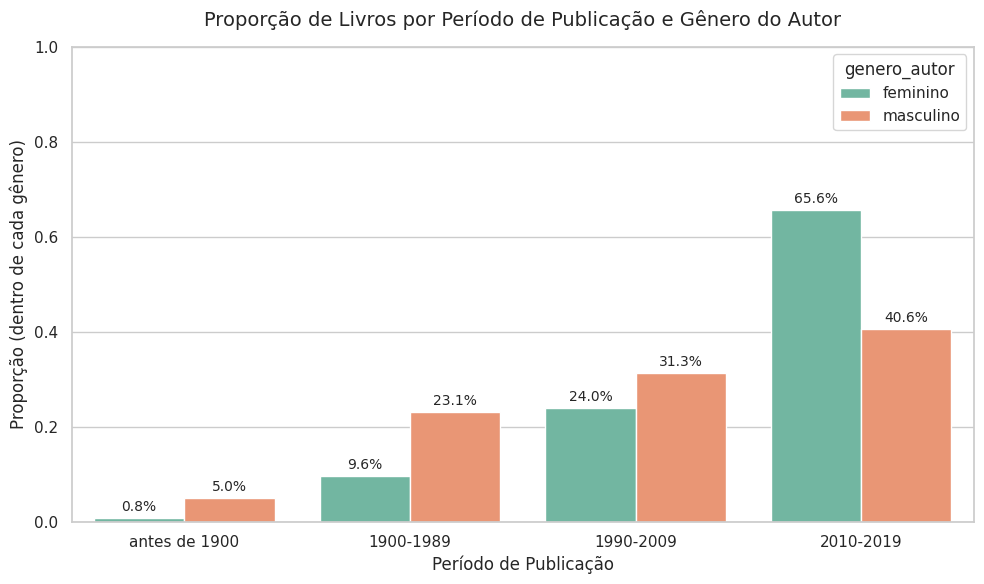

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcula a tabela cruzada com as proporções normalizadas por gênero (colunas)
tabela_proporcoes = pd.crosstab(periodo, livros["genero_autor"], normalize="columns").reset_index()

# Transforma os dados para o formato longo (long format) ideal para o Seaborn
df_plot = tabela_proporcoes.melt(id_vars="ano_publicacao", value_name="proporcao", var_name="genero_autor")

# Configura o estilo e tamanho do gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Cria o gráfico de barras
ax = sns.barplot(
    data=df_plot,
    x="ano_publicacao",
    y="proporcao",
    hue="genero_autor",
    palette="Set2"
)

# Ajusta títulos e rótulos
plt.title("Proporção de Livros por Período de Publicação e Gênero do Autor", fontsize=14, pad=15)
plt.xlabel("Período de Publicação", fontsize=12)
plt.ylabel("Proporção (dentro de cada gênero)", fontsize=12)
plt.ylim(0, 1.0)

# Adiciona as porcentagens em cima das barras para facilitar a leitura
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        ax.annotate(f'{altura:.1%}',
                    (p.get_x() + p.get_width() / 2., altura),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=10)

plt.tight_layout()
plt.show()

## Da cobertura à governança

Mais dados não são sempre a resposta. Ampliar um corpus pode reduzir
certas lacunas, mas também pode contrariar direitos, protocolos de acesso
ou interesses das pessoas e comunidades relacionadas aos dados. O
Notebook 04 aprofundará essa passagem da disponibilidade técnica para a
governança, distinguindo os princípios FAIR e CARE.

## Síntese

Uma análise responsável documenta não só o que existe na tabela, mas os
processos que produziram presenças, ausências e possibilidades de acesso.

Leve a matriz ao Notebook 03. Metadados e proveniência tornarão rastreáveis
as decisões de seleção e os limites de cobertura; o Notebook 04 retomará
suas implicações de governança.